In [1]:
import yfinance as yf 
import pandas as pd
import numpy as np 
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

In [2]:
ticker = yf.Ticker('MU')

In [3]:
data = ticker.history(period='1y', interval='1h')

In [4]:
data

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Datetime,,,,,,,
2024-01-04 09:30:00-05:00,83.470001,84.260002,83.043198,83.550003,6325031,0.0,0.0
2024-01-04 10:30:00-05:00,83.550003,83.970001,83.400002,83.690002,2870287,0.0,0.0
2024-01-04 11:30:00-05:00,83.690002,83.959999,83.070000,83.410004,1515494,0.0,0.0
2024-01-04 12:30:00-05:00,83.419899,83.470001,82.959999,83.110001,966710,0.0,0.0
2024-01-04 13:30:00-05:00,83.120003,83.250000,82.860001,82.934998,614521,0.0,0.0
...,...,...,...,...,...,...,...
2025-01-03 11:30:00-05:00,88.589996,89.330002,88.480003,89.050003,1524457,0.0,0.0
2025-01-03 12:30:00-05:00,89.059998,89.419998,88.989998,89.360001,908021,0.0,0.0
2025-01-03 13:30:00-05:00,89.360001,89.925003,89.230103,89.709999,1857703,0.0,0.0


In [5]:
data.isna().sum()

Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64

In [6]:
close = data[['Close']]
close

,Close
Datetime,
2024-01-04 09:30:00-05:00,83.550003
2024-01-04 10:30:00-05:00,83.690002
2024-01-04 11:30:00-05:00,83.410004
2024-01-04 12:30:00-05:00,83.110001
2024-01-04 13:30:00-05:00,82.934998
...,...
2025-01-03 11:30:00-05:00,89.050003
2025-01-03 12:30:00-05:00,89.360001
2025-01-03 13:30:00-05:00,89.709999


In [7]:
close.index = pd.to_datetime(close.index)

In [8]:
close = close.sort_index()

<Axes: xlabel='Datetime'>

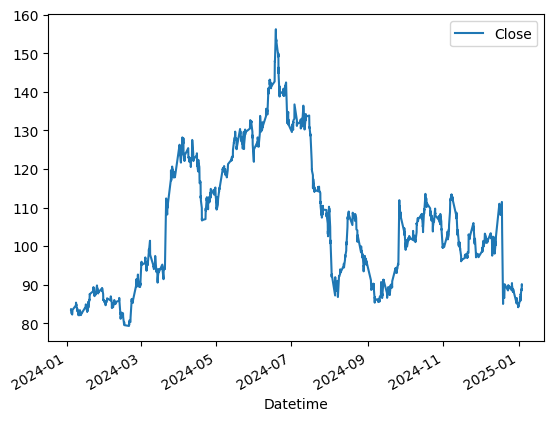

In [9]:
close.plot()

In [10]:
from statsmodels.tsa.stattools import adfuller

In [11]:
adfuller(close.dropna())

(np.float64(-1.7873244393853398),
 np.float64(0.386772668057657),
 0,
 1751,
 {'1%': np.float64(-3.434090098474972),
  '5%': np.float64(-2.8631920451777195),
  '10%': np.float64(-2.5676494998436072)},
 np.float64(5895.102979605435))

<Axes: xlabel='Datetime'>

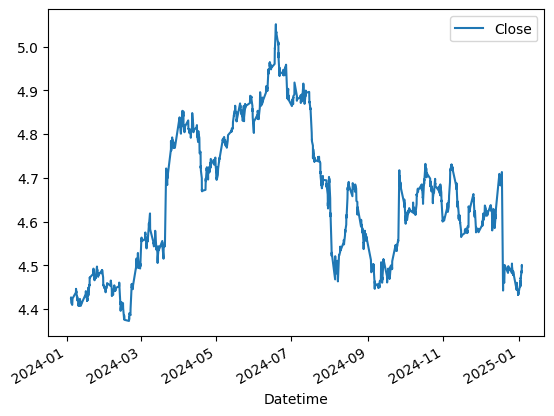

In [12]:
close_log = np.log(close)
close_log.plot()

<Axes: xlabel='Datetime'>

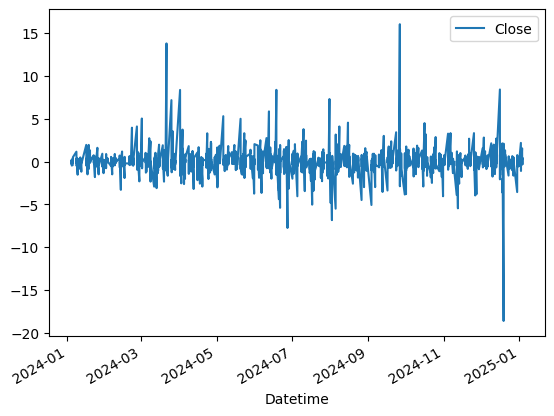

In [13]:
close_diff1 = close.diff()
close_diff1.plot()

In [14]:
adfuller(close_diff1.dropna())

(np.float64(-41.91078251630327),
 0.0,
 0,
 1750,
 {'1%': np.float64(-3.4340922388213175),
  '5%': np.float64(-2.863192990001633),
  '10%': np.float64(-2.5676500029387754)},
 np.float64(5895.925598282898))

<Axes: xlabel='Datetime'>

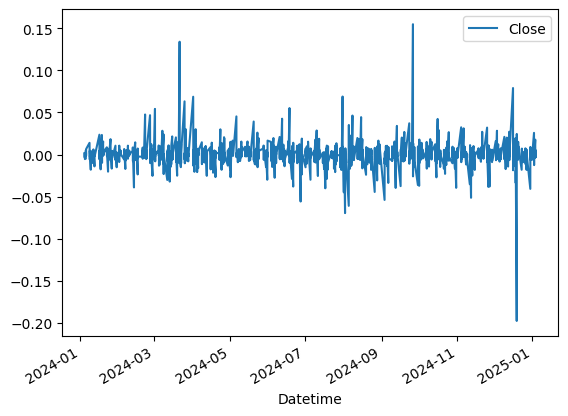

In [15]:
close_log_diff1 = close_log.diff()
close_log_diff1.plot()

In [16]:
adfuller(close_log_diff1.dropna())

(np.float64(-41.91156480185987),
 0.0,
 0,
 1750,
 {'1%': np.float64(-3.4340922388213175),
  '5%': np.float64(-2.863192990001633),
  '10%': np.float64(-2.5676500029387754)},
 np.float64(-10185.268472502365))

In [17]:
decomp = seasonal_decompose(close, period=24)

In [18]:
trend = decomp.trend
seasonal = decomp.seasonal
noise = decomp.resid

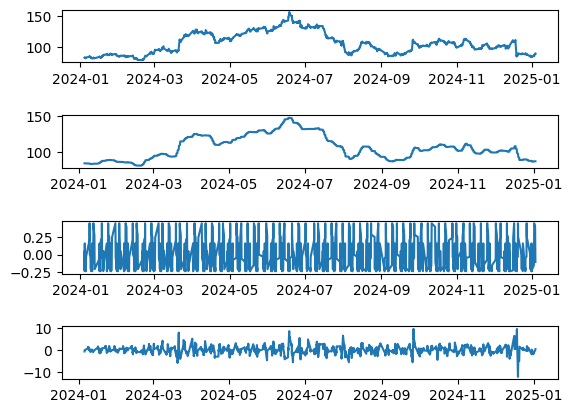

In [19]:
fig, ax = plt.subplots(nrows=4, ncols=1)
ax[0].plot(close)
ax[1].plot(trend)
ax[2].plot(seasonal)
ax[3].plot(noise)
plt.subplots_adjust(wspace=1, hspace=1)
plt.show()

In [20]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_squared_error

(-0.1, 0.1)

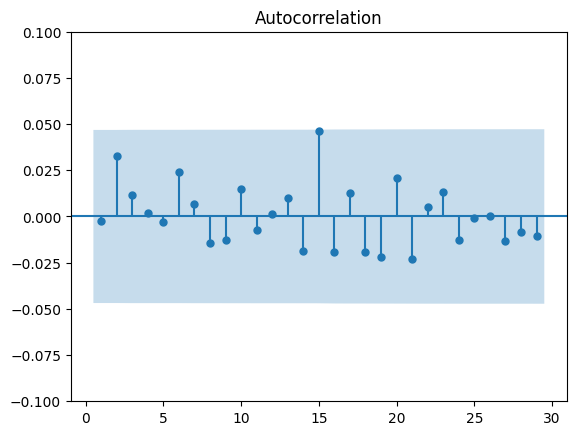

In [21]:
plot_acf(close_diff1.dropna(), lags=np.arange(1, 30));
plt.ylim(-0.1, 0.1)

In [22]:
q_vals = [1, 2]

(-0.1, 0.1)

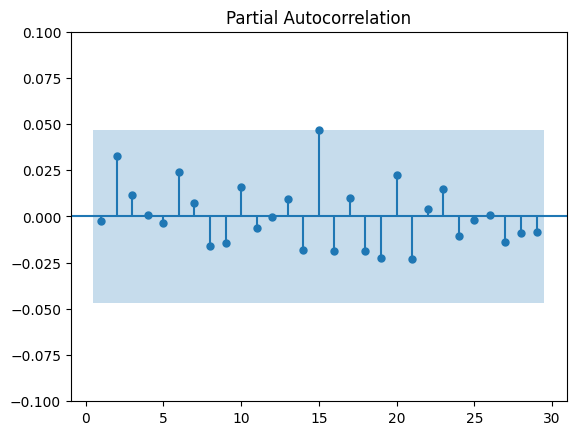

In [23]:
plot_pacf(close_diff1.dropna(), lags=np.arange(1, 30));
plt.ylim(-0.1, 0.1)

In [24]:
p_vals = [1, 2]
d_vals = [1]

C:\Users\lambo\AppData\Local\Temp\ipykernel_36464\1364500632.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly = close.resample('M').mean()


<Axes: xlabel='Datetime'>

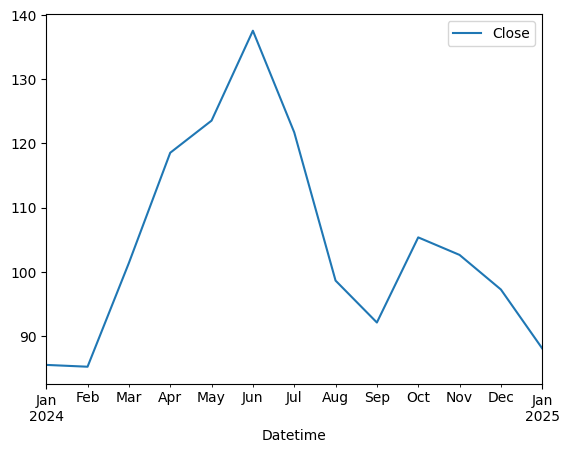

In [25]:
monthly = close.resample('M').mean()
monthly.plot()

In [26]:
best_rmse = float('inf')
best_model = None

train = close[:len(close)-50]

test = close[len(close)-50:]

for p in p_vals:
  for d in d_vals:
    for q in q_vals:
      print(f'Trying parameters: p={p}, d={d}, q={q}')
      model = ARIMA(train, order=(p,d,q)).fit()

      forecast = model.get_forecast(steps=len(test))
      forecast_values = forecast.predicted_mean

      rmse = np.sqrt(mean_squared_error(test, forecast_values))

      if rmse < best_rmse:
        best_rmse = rmse
        best_model = model

C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g

Trying parameters: p=1, d=1, q=1
Trying parameters: p=1, d=1, q=2
Trying parameters: p=2, d=1, q=1


C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g.

Trying parameters: p=2, d=1, q=2


C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


In [52]:
best_model.model_orders

{'trend': 0,
 'exog': 0,
 'ar': 1,
 'ma': 2,
 'seasonal_ar': 0,
 'seasonal_ma': 0,
 'reduced_ar': 1,
 'reduced_ma': 2,
 'exog_variance': 0,
 'measurement_variance': 0,
 'variance': 1}

In [56]:
best_model = ARIMA(data['Close'], order=(1,1,2)).fit()

C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g

In [27]:
best_rmse

np.float64(2.3260224127786477)

C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


<Axes: xlabel='Datetime'>

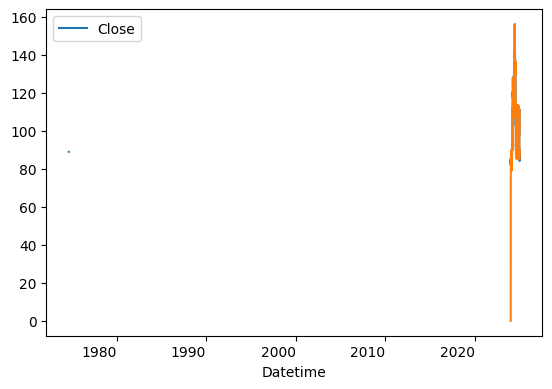

In [40]:
close.plot()
best_model.fittedvalues.plot()
best_model.forecast(2).plot()

In [47]:
best_model.forecast(2)

C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


1702    89.016578
1703    89.019449
Name: predicted_mean, dtype: float64

In [57]:
len(best_model.fittedvalues)

1752

In [50]:
len(data["Close"])

1752

C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\lambo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
C:\Users\lambo\AppData\Local\Temp\ipykernel_36464\2998208208.py:5: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  plt.plot(pd.date_range(start=data.index[-1], periods=3, freq='H'), np.concatenate([np.array([data['Close'][-1]]), next_2_predictions]), 

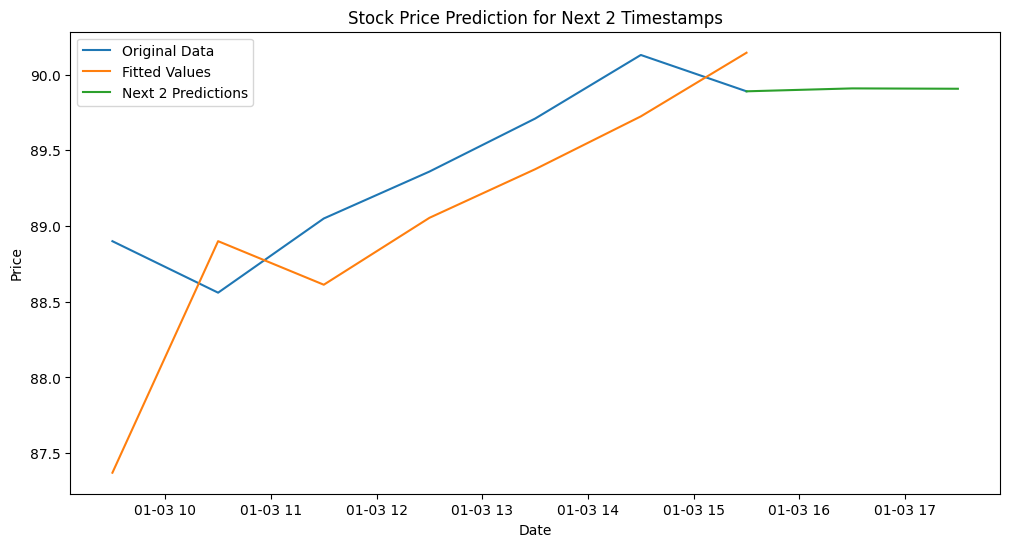

In [79]:
next_2_predictions = best_model.forecast(2)
plt.figure(figsize=(12, 6)) 
plt.plot(data['Close'][-7:], label='Original Data') 
plt.plot(best_model.fittedvalues[-7:], label='Fitted Values') 
plt.plot(pd.date_range(start=data.index[-1], periods=3, freq='H'), np.concatenate([np.array([data['Close'][-1]]), next_2_predictions]), label='Next 2 Predictions')
plt.xlabel('Date') 
plt.ylabel('Price') 
plt.title('Stock Price Prediction for Next 2 Timestamps') 
plt.legend()

In [72]:
np.concatenate([np.array([5]), next_2_predictions.values])

array([ 5.        , 89.90923109, 89.90693054])

In [63]:
data['Close']

Datetime
2024-01-04 09:30:00-05:00    83.550003
2024-01-04 10:30:00-05:00    83.690002
2024-01-04 11:30:00-05:00    83.410004
2024-01-04 12:30:00-05:00    83.110001
2024-01-04 13:30:00-05:00    82.934998
                               ...    
2025-01-03 11:30:00-05:00    89.050003
2025-01-03 12:30:00-05:00    89.360001
2025-01-03 13:30:00-05:00    89.709999
2025-01-03 14:30:00-05:00    90.129997
2025-01-03 15:30:00-05:00    89.889999
Name: Close, Length: 1752, dtype: float64

In [64]:
data.index[-1]

Timestamp('2025-01-03 15:30:00-0500', tz='America/New_York')

In [66]:
pd.date_range(start=data.index[-1], periods=3, freq='H')

C:\Users\lambo\AppData\Local\Temp\ipykernel_36464\1503320158.py:1: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  pd.date_range(start=data.index[-1], periods=3, freq='H')


DatetimeIndex(['2025-01-03 15:30:00-05:00', '2025-01-03 16:30:00-05:00',
               '2025-01-03 17:30:00-05:00'],
              dtype='datetime64[ns, America/New_York]', freq='h')

In [78]:
np.array([data['Close'][-1]])

C:\Users\lambo\AppData\Local\Temp\ipykernel_36464\40962098.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  np.array([data['Close'][-1]])


array([89.88999939])